In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("POP.csv")

In [3]:
df.head(10)

,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ranking,NaN,Economy,(thousands),NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,IND,1,NaN,India,"1,417,173",NaN
5,CHN,2,NaN,China,"1,412,175",NaN
6,USA,3,NaN,United States,"333,288",NaN
7,IDN,4,NaN,Indonesia,"275,501",NaN
8,PAK,5,NaN,Pakistan,"235,825",NaN
9,NGA,6,NaN,Nigeria,"218,541",NaN


In [5]:
df.shape

(328, 6)

In [12]:
print(df.columns.tolist())

['Unnamed: 0', 'Population 2022', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


In [19]:
df.columns

Index(['country_code', 'ranking', 'country', 'population_thousands'], dtype='str')

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 220 entries, 2 to 239
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   country_code          217 non-null    str  
 1   ranking               220 non-null    str  
 2   country               218 non-null    str  
 3   population_thousands  218 non-null    str  
dtypes: str(4)
memory usage: 13.5 KB


In [9]:
df.isnull().sum()

Unnamed: 0          99
Population 2022    108
Unnamed: 2         328
Unnamed: 3          98
Unnamed: 4          98
Unnamed: 5         326
dtype: int64

In [10]:
df.describe()

,Unnamed: 2
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


In [11]:
df.head(15)


,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ranking,NaN,Economy,(thousands),NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,IND,1,NaN,India,"1,417,173",NaN
5,CHN,2,NaN,China,"1,412,175",NaN
6,USA,3,NaN,United States,"333,288",NaN
7,IDN,4,NaN,Indonesia,"275,501",NaN
8,PAK,5,NaN,Pakistan,"235,825",NaN
9,NGA,6,NaN,Nigeria,"218,541",NaN


In [ ]:
df = df.iloc[4:, [0, 1, 3, 4]].copy()

df.columns = ['Country_Code', 'Ranking', 'Country', 'Population']

df.reset_index(drop=True, inplace=True)

In [6]:
print(df['Population 2022'].duplicated().sum())

107


In [53]:
df['Population 2022'] = pd.to_numeric(
    df['Population 2022'].astype(str).str.replace(',', ''),
    errors='coerce'
)

In [63]:
df['Population 2022'].head()

0    NaN
1    NaN
2    NaN
3    NaN
4    1.0
Name: Population 2022, dtype: float64

In [48]:
df = pd.read_csv("POP.csv", header=None, skiprows=5, usecols=[0, 1, 3, 4],
                 names=["code", "ranking", "country", "population_thousands"])

In [49]:
df = df.dropna(subset=["population_thousands"])
df["ranking"] = pd.to_numeric(df["ranking"], errors="coerce")


In [50]:
aggregates = df[df["ranking"].isna()].copy()
countries = df[df["ranking"].notna()].copy()


In [51]:
for d in (countries, aggregates):
    d["population_thousands"] = (d["population_thousands"].astype(str)
                                 .str.replace(",", "", regex=False)
                                 .str.strip()
                                 .astype(float))
countries["ranking"] = countries["ranking"].astype(int)


In [52]:
countries = countries.rename(columns={
    "code": "country_code", 
    "population_thousands": "population_2022_thousands"
})
countries["population_2022_millions"] = countries["population_2022_thousands"] / 1000
countries = countries.reset_index(drop=True)

In [53]:
print(f"Countries parsed: {countries.shape[0]} | Aggregates removed: {aggregates.shape[0]}")
print(f"Remaining missing values: {countries.isna().sum().sum()}")

Countries parsed: 217 | Aggregates removed: 12
Remaining missing values: 0


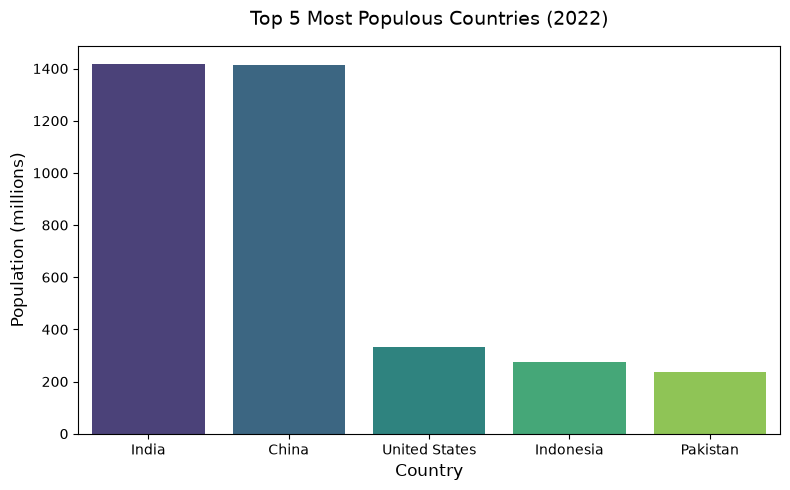

In [54]:
# Extract the top 5 smallest ranks (1 to 5)
top5 = countries.nsmallest(5, "ranking")

plt.figure(figsize=(8, 5))
sns.barplot(data=top5, x="country", y="population_2022_millions", hue="country", palette="viridis", legend=False)
plt.title("Top 5 Most Populous Countries (2022)", fontsize=14, pad=15)
plt.xlabel("Country", fontsize=12)
plt.ylabel("Population (millions)", fontsize=12)
plt.tight_layout()
plt.show()


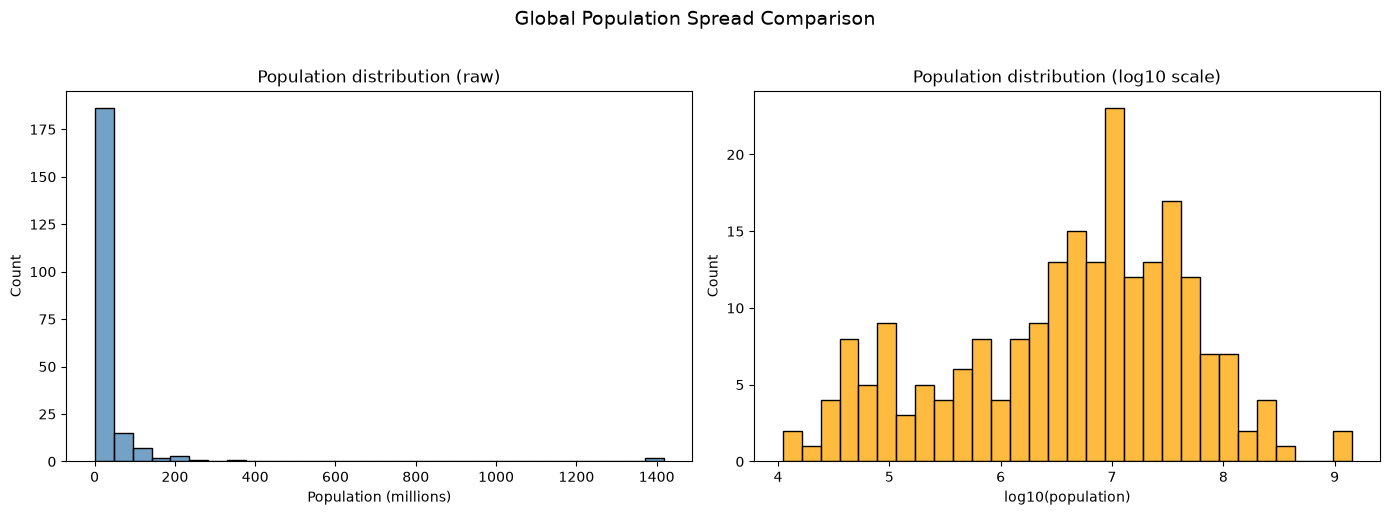

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Subplot: Raw Population Scale
sns.histplot(data=countries, x="population_2022_millions", ax=axes[0], color="steelblue", bins=30)
axes[0].set_title("Population distribution (raw)", fontsize=12)
axes[0].set_xlabel("Population (millions)")
axes[0].set_ylabel("Count")

# Right Subplot: Log10 Population Scale
countries["log10_population"] = np.log10(countries["population_2022_thousands"] * 1000)
sns.histplot(data=countries, x="log10_population", ax=axes[1], color="orange", bins=30)
axes[1].set_title("Population distribution (log10 scale)", fontsize=12)
axes[1].set_xlabel("log10(population)")
axes[1].set_ylabel("Count")

plt.suptitle("Global Population Spread Comparison", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()
